<a href="https://colab.research.google.com/github/soham20042005/Neural-Network-using-NumPY/blob/main/Neural_Network_using_NumPy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Neural Network from Scratch — NumPy Only
MNIST handwritten-digit classification
This notebook builds a small, reusable fully connected neural-network framework using NumPy for all model mathematics and training.

Implemented: dense layers, ReLU / sigmoid / tanh / softmax, cross-entropy, manual backpropagation, gradient checking, SGD / RMSProp / Adam, batch normalization, dropout, mini-batch training, evaluation, and plots.

Benchmark: an optional PyTorch implementation is included at the end. PyTorch is used only for the comparison—not by the NumPy model.

1. Imports and reproducibility
The core implementation depends only on NumPy. Matplotlib is used for plots; the MNIST download uses Python's standard library.

In [1]:
from pathlib import Path
import gzip
import struct
import urllib.request
import time
import copy
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)

NumPy: 2.4.6


2. Download and load MNIST
MNIST images are 28×28 grayscale images. Each image is flattened to 784 input features and pixel values are scaled to [0, 1].

In [2]:
DATA_DIR = Path("data/mnist")
DATA_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"

def download_mnist_file(filename):
    path = DATA_DIR / filename
    if not path.exists():
        print("Downloading", filename)
        urllib.request.urlretrieve(BASE_URL + filename, path)
    return path

def read_idx_images(path):
    with gzip.open(path, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError(f"Unexpected image-file magic number: {magic}")
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(count, rows * cols).astype(np.float32) / 255.0

def read_idx_labels(path):
    with gzip.open(path, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError(f"Unexpected label-file magic number: {magic}")
        return np.frombuffer(f.read(), dtype=np.uint8).astype(np.int64)

paths = {k: download_mnist_file(v) for k, v in FILES.items()}
X_train_full = read_idx_images(paths["train_images"])
y_train_full = read_idx_labels(paths["train_labels"])
X_test = read_idx_images(paths["test_images"])
y_test = read_idx_labels(paths["test_labels"])

# Hold out 10% of the official training set for validation.
perm = np.random.permutation(len(X_train_full))
val_size = 6000
val_idx, train_idx = perm[:val_size], perm[val_size:]
X_val, y_val = X_train_full[val_idx], y_train_full[val_idx]
X_train, y_train = X_train_full[train_idx], y_train_full[train_idx]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (54000, 784) (54000,)
Validation: (6000, 784) (6000,)
Test: (10000, 784) (10000,)


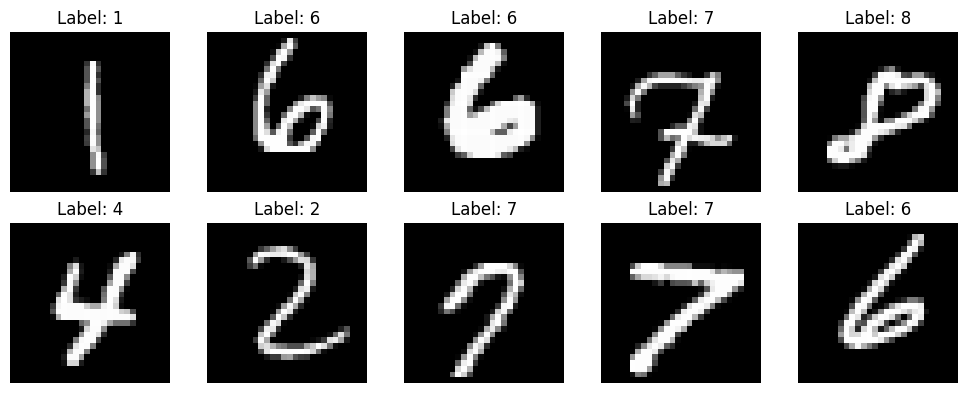

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), X_train[:10], y_train[:10]):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

3. One-hot encoding and numerical helpers

In [4]:
def one_hot(y, num_classes=10):
    out = np.zeros((len(y), num_classes), dtype=np.float32)
    out[np.arange(len(y)), y] = 1.0
    return out

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def cross_entropy(y_true, probabilities, eps=1e-12):
    probabilities = np.clip(probabilities, eps, 1.0)
    return -np.mean(np.sum(y_true * np.log(probabilities), axis=1))

def accuracy(y_true_labels, probabilities):
    return np.mean(np.argmax(probabilities, axis=1) == y_true_labels)

4. Activation functions
Each activation exposes a forward operation and the derivative needed by backpropagation. Softmax is handled together with cross-entropy at the output layer for a stable, simple gradient.

In [5]:
class ReLU:
    def forward(self, z):
        self.mask = z > 0
        return z * self.mask
    def backward(self, grad):
        return grad * self.mask

class Sigmoid:
    def forward(self, z):
        z = np.clip(z, -500, 500)
        self.out = 1.0 / (1.0 + np.exp(-z))
        return self.out
    def backward(self, grad):
        return grad * self.out * (1.0 - self.out)

class Tanh:
    def forward(self, z):
        self.out = np.tanh(z)
        return self.out
    def backward(self, grad):
        return grad * (1.0 - self.out ** 2)

def make_activation(name):
    activations = {"relu": ReLU, "sigmoid": Sigmoid, "tanh": Tanh}
    if name.lower() not in activations:
        raise ValueError(f"Unsupported hidden activation: {name}")
    return activations[name.lower()]()

5. Layers: Dense, Batch Normalization, and Dropout
Batch normalization uses mini-batch statistics during training and running statistics during inference. Dropout uses inverted dropout, so no scaling is needed at inference.

In [7]:
class Dense:
    def __init__(self, n_in, n_out, init="he", rng=None):
        rng = rng or np.random.default_rng()
        if init == "he":
            scale = np.sqrt(2.0 / n_in)
        elif init == "xavier":
            scale = np.sqrt(2.0 / (n_in + n_out))
        else:
            scale = 0.01
        self.W = rng.normal(0, scale, size=(n_in, n_out)).astype(np.float32)
        self.b = np.zeros((1, n_out), dtype=np.float32)
        self.params = {"W": self.W, "b": self.b}
        self.grads = {}

    def forward(self, x, training=True):
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad):
        m = self.x.shape[0]
        self.grads["W"] = self.x.T @ grad / m
        self.grads["b"] = np.sum(grad, axis=0, keepdims=True) / m
        return grad @ self.W.T


class BatchNorm:
    def __init__(self, features, momentum=0.9, eps=1e-5):
        self.gamma = np.ones((1, features), dtype=np.float32)
        self.beta = np.zeros((1, features), dtype=np.float32)
        self.params = {"gamma": self.gamma, "beta": self.beta}
        self.grads = {}
        self.momentum, self.eps = momentum, eps
        self.running_mean = np.zeros((1, features), dtype=np.float32)
        self.running_var = np.ones((1, features), dtype=np.float32)

    def forward(self, x, training=True):
        if training:
            self.mean = np.mean(x, axis=0, keepdims=True)
            self.var = np.var(x, axis=0, keepdims=True)
            self.x_centered = x - self.mean
            self.inv_std = 1.0 / np.sqrt(self.var + self.eps)
            self.x_hat = self.x_centered * self.inv_std
            self.running_mean = self.momentum * self.running_mean + (1-self.momentum) * self.mean
            self.running_var = self.momentum * self.running_var + (1-self.momentum) * self.var
        else:
            self.x_hat = (x - self.running_mean) / np.sqrt(self.running_var + self.eps)
        return self.gamma * self.x_hat + self.beta

    def backward(self, grad):
        m = grad.shape[0]
        self.grads["gamma"] = np.sum(grad * self.x_hat, axis=0, keepdims=True) / m
        self.grads["beta"] = np.sum(grad, axis=0, keepdims=True) / m
        dxhat = grad * self.gamma
        # Compact derivative of batch normalization.
        dx = (self.inv_std / m) * (
            m * dxhat
            - np.sum(dxhat, axis=0, keepdims=True)
            - self.x_hat * np.sum(dxhat * self.x_hat, axis=0, keepdims=True)
        )
        return dx


class Dropout:
    def __init__(self, rate, rng=None):
        if not 0 <= rate < 1:
            raise ValueError("Dropout rate must be in [0, 1).")
        self.rate = rate
        self.rng = rng or np.random.default_rng()

    def forward(self, x, training=True):
        if training and self.rate > 0:
            self.mask = (self.rng.random(x.shape) >= self.rate).astype(np.float32)
            self.mask /= (1.0 - self.rate)
            return x * self.mask
        self.mask = None
        return x

    def backward(self, grad):
        return grad if self.mask is None else grad * self.mask

6. Optimizers: SGD, RMSProp, and Adam

In [6]:
class Optimizer:
    def update(self, layers):
        raise NotImplementedError

class SGD(Optimizer):
    def __init__(self, lr=0.01):
        self.lr = lr
    def update(self, layers):
        for layer in layers:
            for name, param in layer.params.items():
                param -= self.lr * layer.grads[name]

class RMSProp(Optimizer):
    def __init__(self, lr=0.001, beta=0.9, eps=1e-8):
        self.lr, self.beta, self.eps = lr, beta, eps
        self.cache = {}
    def update(self, layers):
        for li, layer in enumerate(layers):
            for name, param in layer.params.items():
                key = (li, name)
                grad = layer.grads[name]
                self.cache.setdefault(key, np.zeros_like(param))
                self.cache[key] = self.beta*self.cache[key] + (1-self.beta)*(grad**2)
                param -= self.lr * grad / (np.sqrt(self.cache[key]) + self.eps)

class Adam(Optimizer):
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, 0
    def update(self, layers):
        self.t += 1
        for li, layer in enumerate(layers):
            for name, param in layer.params.items():
                key = (li, name)
                grad = layer.grads[name]
                self.m.setdefault(key, np.zeros_like(param))
                self.v.setdefault(key, np.zeros_like(param))
                self.m[key] = self.beta1*self.m[key] + (1-self.beta1)*grad
                self.v[key] = self.beta2*self.v[key] + (1-self.beta2)*(grad**2)
                m_hat = self.m[key] / (1-self.beta1**self.t)
                v_hat = self.v[key] / (1-self.beta2**self.t)
                param -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

def make_optimizer(name, lr):
    name = name.lower()
    if name == "sgd": return SGD(lr)
    if name == "rmsprop": return RMSProp(lr)
    if name == "adam": return Adam(lr)
    raise ValueError("Optimizer must be sgd, rmsprop, or adam.")

7. Neural network model
Architecture is configurable. Hidden blocks are Dense → optional BatchNorm → activation → optional Dropout. The output layer is Dense → Softmax.

In [8]:
class NeuralNetwork:
    def __init__(self, layer_sizes, activation="relu", optimizer="adam",
                 learning_rate=0.001, batch_norm=False, dropout=0.0, seed=42):
        if len(layer_sizes) < 2:
            raise ValueError("Provide at least input and output dimensions.")
        self.rng = np.random.default_rng(seed)
        self.layers = []
        self.blocks = []
        self.activation_name = activation
        self.batch_norm = batch_norm
        self.dropout_rate = dropout

        for i in range(len(layer_sizes)-1):
            dense = Dense(layer_sizes[i], layer_sizes[i+1],
                          init="he" if activation == "relu" else "xavier",
                          rng=self.rng)
            self.layers.append(dense)
            if i < len(layer_sizes)-2:
                block = [dense]
                if batch_norm:
                    bn = BatchNorm(layer_sizes[i+1])
                    self.layers.append(bn)
                    block.append(bn)
                act = make_activation(activation)
                block.append(act)
                if dropout > 0:
                    drop = Dropout(dropout, rng=self.rng)
                    block.append(drop)
                self.blocks.append(block)
        self.optimizer = make_optimizer(optimizer, learning_rate)
        self.history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}

    def forward(self, x, training=True):
        out = x
        # Every non-output layer is followed by its associated optional operations.
        for block in self.blocks:
            for layer in block:
                if isinstance(layer, (Dense, BatchNorm)):
                    out = layer.forward(out, training)
                else:
                    out = layer.forward(out)
        out = self.layers[-1].forward(out, training)
        return softmax(out)

    def backward(self, y_onehot, probabilities):
        grad = (probabilities - y_onehot)  # mean is applied in Dense.backward
        grad = self.layers[-1].backward(grad)
        for block in reversed(self.blocks):
            for layer in reversed(block):
                grad = layer.backward(grad)
        return grad

    def _train_batch(self, x, y):
        probs = self.forward(x, training=True)
        self.backward(y, probs)
        self.optimizer.update(self.layers)
        return cross_entropy(y, probs)

    def predict_proba(self, x, batch_size=1024):
        outputs = []
        for start in range(0, len(x), batch_size):
            outputs.append(self.forward(x[start:start+batch_size], training=False))
        return np.vstack(outputs)

    def predict(self, x):
        return np.argmax(self.predict_proba(x), axis=1)

    def evaluate(self, x, y):
        probs = self.predict_proba(x)
        return cross_entropy(one_hot(y), probs), accuracy(y, probs)

    def fit(self, x_train, y_train, x_val, y_val, epochs=15, batch_size=128, verbose=True):
        y_train_oh = one_hot(y_train)
        for epoch in range(1, epochs+1):
            order = self.rng.permutation(len(x_train))
            batch_losses = []
            for start in range(0, len(order), batch_size):
                idx = order[start:start+batch_size]
                batch_losses.append(self._train_batch(x_train[idx], y_train_oh[idx]))
            train_loss, train_acc = self.evaluate(x_train, y_train)
            val_loss, val_acc = self.evaluate(x_val, y_val)
            self.history["loss"].append(train_loss)
            self.history["val_loss"].append(val_loss)
            self.history["accuracy"].append(train_acc)
            self.history["val_accuracy"].append(val_acc)
            if verbose:
                print(f"Epoch {epoch:02d}/{epochs} | "
                      f"loss {train_loss:.4f} | acc {train_acc:.4f} | "
                      f"val_loss {val_loss:.4f} | val_acc {val_acc:.4f}")
        return self.history

8. Unit test: gradient checking
Before training MNIST, check the Dense-layer weight gradient against a finite-difference numerical approximation. This catches common backpropagation mistakes.

In [12]:
def gradient_check_dense():
    r = np.random.default_rng(7)
    x = r.normal(size=(4, 3)).astype(np.float64)
    y = r.normal(size=(4, 2)).astype(np.float64)
    layer = Dense(3, 2, init="xavier", rng=r)
    layer.W = layer.W.astype(np.float64)
    layer.b = layer.b.astype(np.float64)
    layer.params = {"W": layer.W, "b": layer.b}

    out = layer.forward(x)
    loss = np.mean((out-y)**2) / 2

    # The true derivative of the element-wise loss with respect to out is:
    # (out - y) / out.size
    # Since layer.backward(grad) will internally divide by len(x), we scale
    # the gradient up by len(x) to cancel the duplicate division.
    grad_out = ((out - y) / out.size) * len(x)

    layer.backward(grad_out)
    analytical = layer.grads["W"].copy()

    numerical = np.zeros_like(layer.W)
    eps = 1e-5
    for i in range(layer.W.shape[0]):
        for j in range(layer.W.shape[1]):
            original = layer.W[i, j]
            layer.W[i, j] = original + eps
            plus = np.mean((layer.forward(x)-y)**2) / 2
            layer.W[i, j] = original - eps
            minus = np.mean((layer.forward(x)-y)**2) / 2
            layer.W[i, j] = original
            numerical[i, j] = (plus-minus)/(2*eps)

    rel_error = np.linalg.norm(analytical-numerical) / (
        np.linalg.norm(analytical)+np.linalg.norm(numerical)+1e-12)
    print("Relative gradient error:", rel_error)
    assert rel_error < 1e-6, "Gradient check failed"
    print("Gradient check passed.")

gradient_check_dense()

Relative gradient error: 1.574909631722705e-11
Gradient check passed.


9. Train the NumPy network
Start with a moderate architecture. Increase epochs or tune hyperparameters if you need a higher score. Training a NumPy network is CPU-based and can take several minutes depending on your machine.

In [13]:
model = NeuralNetwork(
    layer_sizes=[784, 256, 128, 10],
    activation="relu",
    optimizer="adam",
    learning_rate=0.001,
    batch_norm=True,
    dropout=0.2,
    seed=SEED
)

start_time = time.perf_counter()
history = model.fit(
    X_train, y_train, X_val, y_val,
    epochs=15,
    batch_size=128
)
numpy_train_seconds = time.perf_counter() - start_time
print(f"NumPy training time: {numpy_train_seconds:.1f} seconds")

Epoch 01/15 | loss 0.1592 | acc 0.9531 | val_loss 0.1720 | val_acc 0.9520
Epoch 02/15 | loss 0.1019 | acc 0.9692 | val_loss 0.1211 | val_acc 0.9637
Epoch 03/15 | loss 0.0844 | acc 0.9735 | val_loss 0.1125 | val_acc 0.9640
Epoch 04/15 | loss 0.0647 | acc 0.9796 | val_loss 0.0937 | val_acc 0.9720
Epoch 05/15 | loss 0.0536 | acc 0.9835 | val_loss 0.0826 | val_acc 0.9765
Epoch 06/15 | loss 0.0440 | acc 0.9863 | val_loss 0.0908 | val_acc 0.9707
Epoch 07/15 | loss 0.0466 | acc 0.9849 | val_loss 0.0900 | val_acc 0.9738
Epoch 08/15 | loss 0.0359 | acc 0.9884 | val_loss 0.0815 | val_acc 0.9753
Epoch 09/15 | loss 0.0337 | acc 0.9889 | val_loss 0.0785 | val_acc 0.9765
Epoch 10/15 | loss 0.0318 | acc 0.9890 | val_loss 0.0920 | val_acc 0.9747
Epoch 11/15 | loss 0.0259 | acc 0.9917 | val_loss 0.0770 | val_acc 0.9772
Epoch 12/15 | loss 0.0251 | acc 0.9914 | val_loss 0.0826 | val_acc 0.9773
Epoch 13/15 | loss 0.0245 | acc 0.9917 | val_loss 0.0845 | val_acc 0.9770
Epoch 14/15 | loss 0.0208 | acc 0.9935

10. Plot training curves

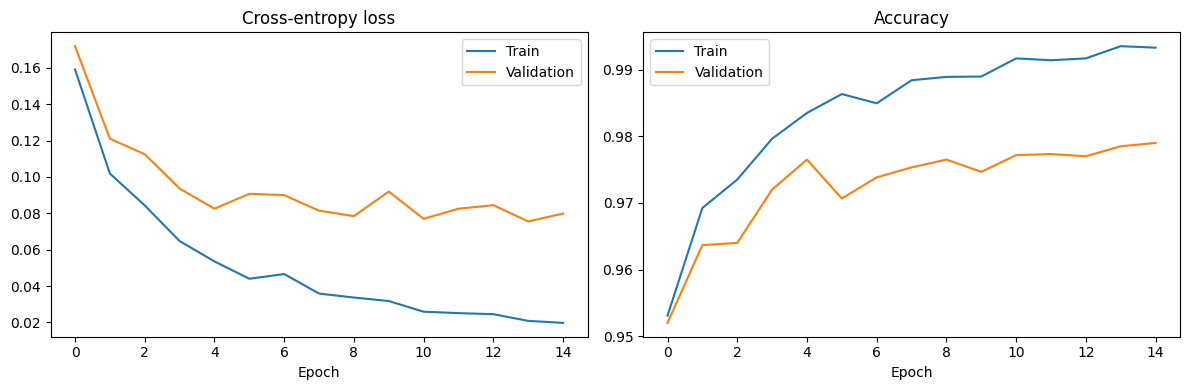

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history["accuracy"], label="Train")
axes[1].plot(history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

11. Final test-set evaluation
The test set is kept out of training and validation. Use it for the final reported result.

In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"NumPy test loss: {test_loss:.4f}")
print(f"NumPy test accuracy: {test_accuracy*100:.2f}%")

NumPy test loss: 0.0849
NumPy test accuracy: 97.58%


12. Confusion matrix and classification report
Scikit-learn is used here only for evaluation metrics, not for neural-network training.

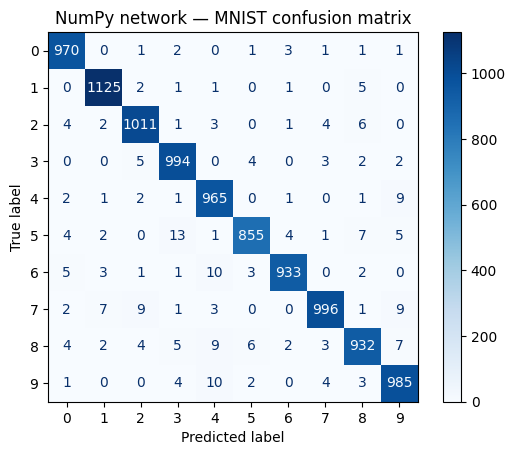

              precision    recall  f1-score   support

           0     0.9778    0.9898    0.9838       980
           1     0.9851    0.9912    0.9881      1135
           2     0.9768    0.9797    0.9782      1032
           3     0.9717    0.9842    0.9779      1010
           4     0.9631    0.9827    0.9728       982
           5     0.9816    0.9585    0.9699       892
           6     0.9873    0.9739    0.9806       958
           7     0.9842    0.9689    0.9765      1028
           8     0.9708    0.9569    0.9638       974
           9     0.9676    0.9762    0.9719      1009

    accuracy                         0.9766     10000
   macro avg     0.9766    0.9762    0.9763     10000
weighted avg     0.9767    0.9766    0.9766     10000



In [16]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues", values_format="d")
plt.title("NumPy network — MNIST confusion matrix")
plt.show()

print(classification_report(y_test, y_pred, digits=4))

13. Inspect misclassified examples

Misclassified examples: 234


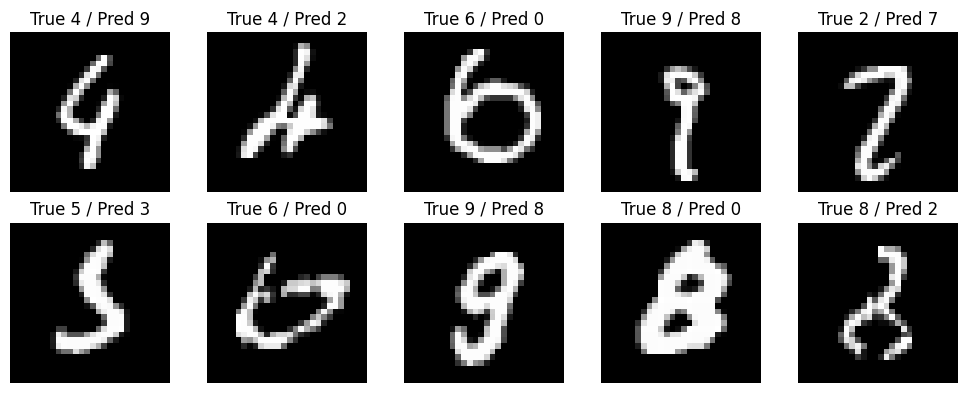

In [17]:
wrong = np.flatnonzero(y_pred != y_test)
print("Misclassified examples:", len(wrong))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"True {y_test[idx]} / Pred {y_pred[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

14.Save model parameters
This saves learned arrays and configuration metadata. The notebook's model class can be reconstructed with the same architecture before loading parameters.

In [18]:
def save_parameters(model, path="numpy_mnist_weights.npz"):
    arrays = {}
    for i, layer in enumerate(model.layers):
        for name, value in getattr(layer, "params", {}).items():
            arrays[f"layer_{i}_{name}"] = value
        if isinstance(layer, BatchNorm):
            arrays[f"layer_{i}_running_mean"] = layer.running_mean
            arrays[f"layer_{i}_running_var"] = layer.running_var
    np.savez(path, **arrays)
    print("Saved:", path)

save_parameters(model)

Saved: numpy_mnist_weights.npz


15.PyTorch benchmark
This section is deliberately separate. It creates an equivalent fully connected architecture with PyTorch for reference. Install PyTorch separately if it is not already available.

For a fair comparison, match the architecture, data split, preprocessing, batch size, epoch count, optimizer, learning rate, and regularization as closely as possible. Exact equality is not expected because implementation details and numerical behavior differ.

In [19]:
# Uncomment if PyTorch is not installed:
# %pip install torch

try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader

    torch.manual_seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("PyTorch:", torch.__version__, "| device:", device)

    class TorchMNIST(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(784, 256),
                nn.BatchNorm1d(256),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(256, 128),
                nn.BatchNorm1d(128),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(128, 10)
            )
        def forward(self, x):
            return self.net(x)

    def make_loader(x, y, shuffle):
        ds = TensorDataset(torch.tensor(x, dtype=torch.float32),
                           torch.tensor(y, dtype=torch.long))
        return DataLoader(ds, batch_size=128, shuffle=shuffle)

    torch_train_loader = make_loader(X_train, y_train, True)
    torch_model = TorchMNIST().to(device)
    criterion = nn.CrossEntropyLoss()
    torch_optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.001)

    torch_start = time.perf_counter()
    for epoch in range(15):
        torch_model.train()
        total_loss = 0.0
        for xb, yb in torch_train_loader:
            xb, yb = xb.to(device), yb.to(device)
            torch_optimizer.zero_grad()
            logits = torch_model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch_optimizer.step()
            total_loss += loss.item() * len(xb)

        torch_model.eval()
        with torch.no_grad():
            xt = torch.tensor(X_test, dtype=torch.float32, device=device)
            yt = torch.tensor(y_test, dtype=torch.long, device=device)
            test_logits = torch_model(xt)
            torch_acc = (test_logits.argmax(1) == yt).float().mean().item()
        print(f"PyTorch epoch {epoch+1:02d}/15 | "
              f"train_loss {total_loss/len(X_train):.4f} | "
              f"test_acc {torch_acc:.4f}")

    torch_train_seconds = time.perf_counter() - torch_start
    print(f"PyTorch training time: {torch_train_seconds:.1f} seconds")
    print(f"PyTorch test accuracy: {torch_acc*100:.2f}%")

except ImportError:
    print("PyTorch is not installed. Skip this optional benchmark or install it separately.")

PyTorch: 2.14.1+cu130 | device: cuda
PyTorch epoch 01/15 | train_loss 0.3019 | test_acc 0.9672
PyTorch epoch 02/15 | train_loss 0.1277 | test_acc 0.9745
PyTorch epoch 03/15 | train_loss 0.0953 | test_acc 0.9768
PyTorch epoch 04/15 | train_loss 0.0784 | test_acc 0.9790
PyTorch epoch 05/15 | train_loss 0.0649 | test_acc 0.9804
PyTorch epoch 06/15 | train_loss 0.0581 | test_acc 0.9799
PyTorch epoch 07/15 | train_loss 0.0505 | test_acc 0.9811
PyTorch epoch 08/15 | train_loss 0.0484 | test_acc 0.9817
PyTorch epoch 09/15 | train_loss 0.0421 | test_acc 0.9815
PyTorch epoch 10/15 | train_loss 0.0378 | test_acc 0.9838
PyTorch epoch 11/15 | train_loss 0.0364 | test_acc 0.9843
PyTorch epoch 12/15 | train_loss 0.0341 | test_acc 0.9824
PyTorch epoch 13/15 | train_loss 0.0299 | test_acc 0.9842
PyTorch epoch 14/15 | train_loss 0.0316 | test_acc 0.9825
PyTorch epoch 15/15 | train_loss 0.0260 | test_acc 0.9807
PyTorch training time: 24.5 seconds
PyTorch test accuracy: 98.07%


16. Results summary
Fill in the table after running both implementations. Do not claim a target accuracy unless your measured test result supports it.

In [20]:
print("RESULTS")
print("-" * 45)
print(f"NumPy | test accuracy: {test_accuracy*100:.2f}%")
print(f"NumPy | test loss:     {test_loss:.4f}")
print(f"NumPy | train seconds: {numpy_train_seconds:.1f}")
if "torch_acc" in globals():
    print(f"PyTorch | test accuracy: {torch_acc*100:.2f}%")
    print(f"PyTorch | train seconds: {torch_train_seconds:.1f}")
    print(f"Accuracy gap (percentage points): "
          f"{abs(test_accuracy-torch_acc)*100:.2f}")

RESULTS
---------------------------------------------
NumPy | test accuracy: 97.58%
NumPy | test loss:     0.0849
NumPy | train seconds: 68.9
PyTorch | test accuracy: 98.07%
PyTorch | train seconds: 24.5
Accuracy gap (percentage points): 0.49
